In [77]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


# Plot the sensitivity of predictability to the initialization month
- [ ] simple plot of ppp regional mean with offset to align time of year
- [ ] plot of "distance" between ppp from different initialization months

In [78]:
import esm4ppe
import matplotlib.pyplot as plt
import calendar
import numpy as np
from dask.diagnostics import ProgressBar
import cartopy.crs as ccrs
import cartopy

In [90]:
import itertools

In [79]:
months36 = list(calendar.month_name[1:])*3

## PPP from different init months withOUT offset

In [83]:
ds = esm4ppe.open_verifyregionalmean('ocean','monthly','basin','ppp',groupby='month')

In [106]:
regions = np.array([[None,'arctic',None],
           [None,'pacific_NoSubP','atlantic_NoSubP'],
           [None,'pacific_NoSubT','atlantic_NoSubT'],
           ['indian_T','pacific_T','atlantic_T'],
           ['indian_SoSubT','pacific_SoSubT','atlantic_SoSubT'],
           [None,'southern',None]])

In [107]:
variable = 'intpp'
region = 'pacific_T'
da = ds[variable].sel(region=region)

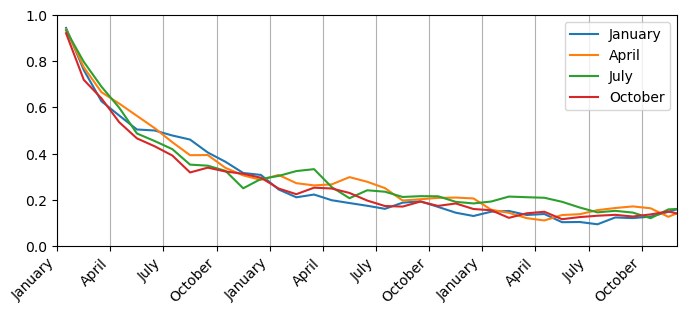

In [113]:
fig,ax = plt.subplots(figsize=(8,3))
for month in da['month']:
    if month==1:
        da = da.sel(lead=slice(0,36))
    ax.plot(da['lead']+0.5,da.sel(month=month),label=calendar.month_name[month.values])
ax.set_xlim([1,36])
ax.set_ylim([0,1])
step = 3
ax.set_xticks(np.arange(1,37,step))
ax.set_xticklabels(list(calendar.month_name)[1::step]*3,rotation=45,ha='right')
ax.grid(axis='x')
ax.legend()

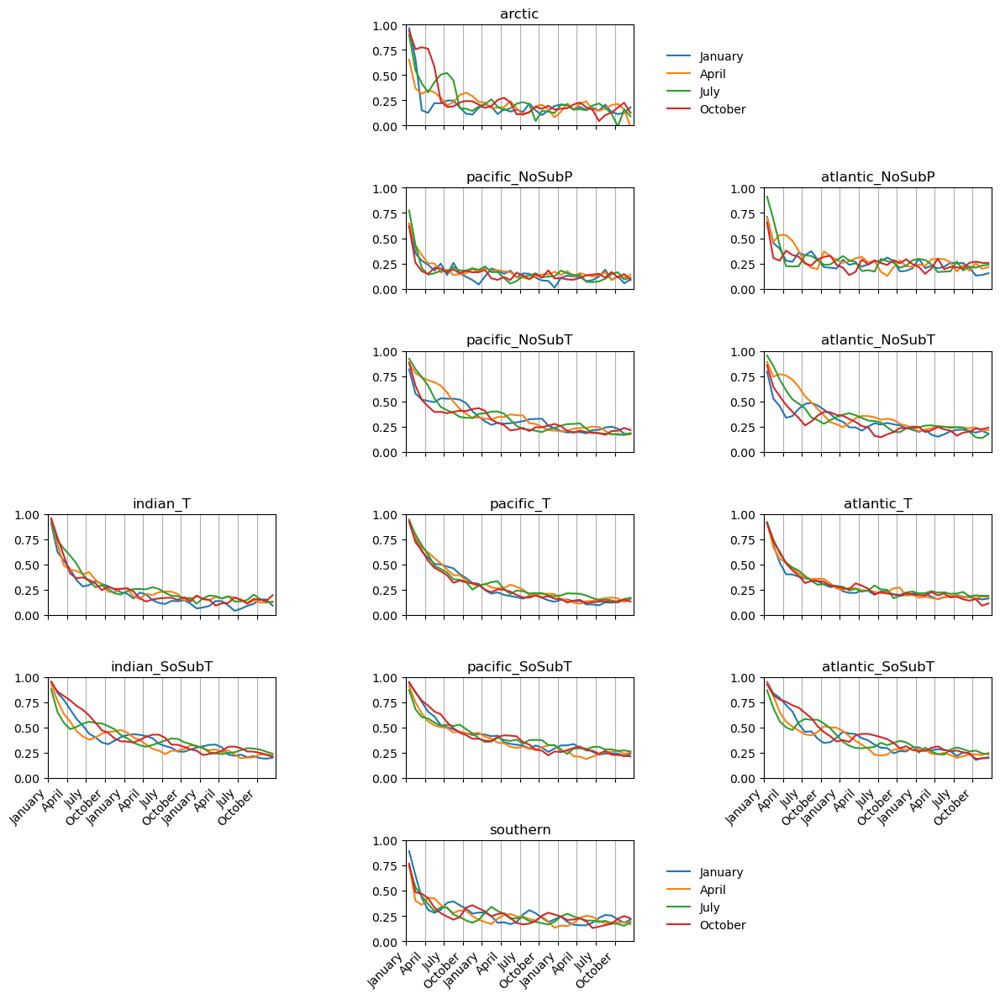

In [123]:
fig,axarr = plt.subplots(figsize=(12,12),nrows=6,ncols=3)
for i,j in itertools.product(range(6),range(3)):
    axnow = axarr[i,j]
    region = regions[i,j]
    if region is None:
        axnow.set_visible(False)
        continue
    else:
        danow = ds[variable].sel(region=region)

        for month in da['month']:
            if month==1:
                danow = danow.sel(lead=slice(0,36))
            axnow.plot(danow['lead']+0.5,danow.sel(month=month),label=calendar.month_name[month.values])
        axnow.set_xlim([1,37])
        axnow.set_ylim([0,1])
        step = 3
        axnow.set_xticks(np.arange(1,37,step))
        axnow.grid(axis='x')
        axnow.set_title(region)
        if region in ['southern','indian_SoSubT','atlantic_SoSubT']:
            axnow.set_xticklabels(list(calendar.month_name)[1::step]*3,rotation=45,ha='right')
        else:
            axnow.set_xticklabels([ ])
            
        if region in ['arctic','southern']:
            axnow.legend(frameon=False,loc='lower left',bbox_to_anchor=(1.1,0))
fig.tight_layout()

## PPP from different init months with offset

In [80]:
ds = esm4ppe.open_verifyregionalmean('ocean','monthly','basin','ppp',groupby='month')

In [81]:
variable = 'intpp'
region = 'pacific_T'
da = ds[variable].sel(region=region)

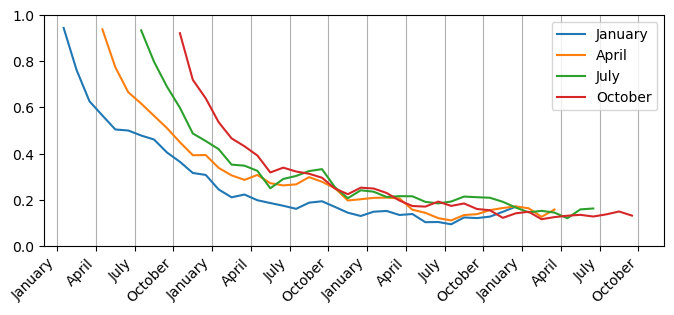

In [82]:
fig,ax = plt.subplots(figsize=(8,3))
for month in da['month']:
    if month==1:
        da = da.sel(lead=slice(0,36))
    offset = month-1
    ax.plot(da['lead']+offset+0.5,da.sel(month=month),label=calendar.month_name[month.values])
ax.set_xlim([0,48])
ax.set_ylim([0,1])
step = 3
ax.set_xticks(np.arange(1,49,step))
ax.set_xticklabels(list(calendar.month_name)[1::step]*4,rotation=45,ha='right')
ax.grid(axis='x')
ax.legend()

# PPP anomalies at specific lead times (relative to mean for that lead time)

In [7]:
static = esm4ppe.open_static('intpp','monthly')
ds = esm4ppe.open_verify('ocean','monthly','ppp',groupby='month')

/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


In [16]:
variable = 'intpp'
da = ds[variable]

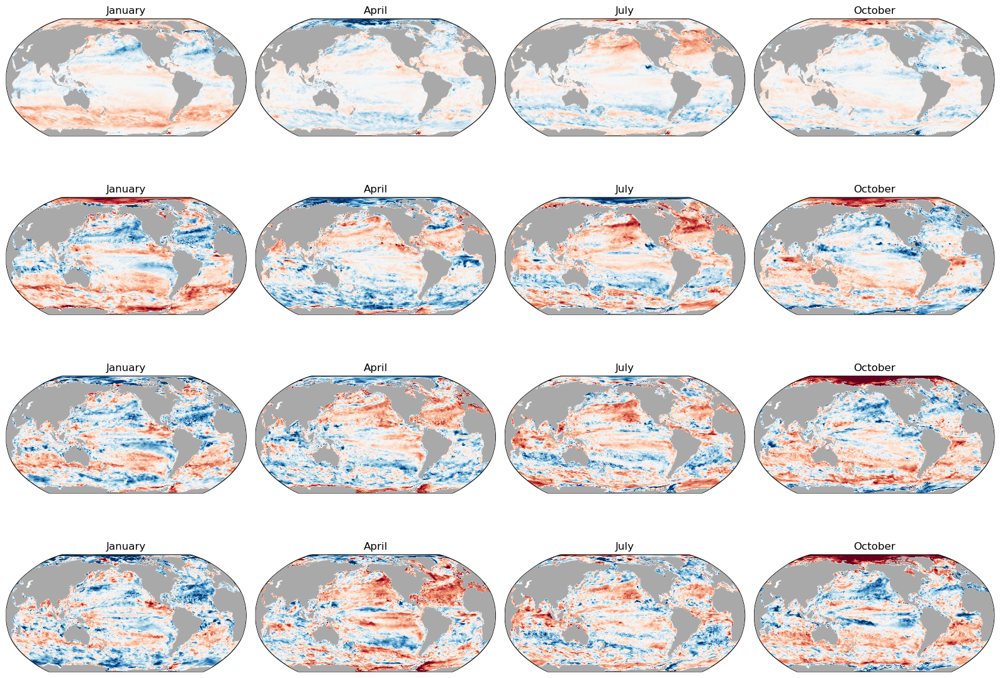

In [17]:
leads = [1,2,3,4]
kw_args = {'cmap':'RdBu_r','vmin':-0.5,'vmax':0.5, 'transform':ccrs.PlateCarree()}
nm = len(da['month'])
nl = len(leads)
fig,axarr = plt.subplots(figsize=(4*nm, 3*nl), ncols=nm, nrows=nl, subplot_kw={'projection':ccrs.Robinson(central_longitude=-150)})
daanom = da - da.mean('month')
X,Y = static['geolon'],static['geolat']
for i,lead in enumerate(leads):
    for j,month in enumerate(daanom['month']):
        axnow = axarr[i,j]
        Z = daanom.sel(month=month,lead=lead)
        im = axnow.pcolormesh(X,Y,Z,**kw_args)
        im.set_clim([-0.5,0.5])
        axnow.set_title(calendar.month_name[month.values])
        axnow.add_feature(cartopy.feature.LAND,zorder=10,facecolor='darkgrey')
fig.tight_layout()

## Differences in zonal mean PPP

In [18]:
import xarray as xr
from xhistogram.xarray import histogram

In [19]:
static = esm4ppe.open_static('intpp','monthly')
ds = esm4ppe.open_verify('ocean','monthly','ppp',groupby='month')
masks = esm4ppe.get_masks('basin',static)

/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


In [20]:
variable = 'intpp'
da = ds[variable]
daanom = da - da.mean('month')
with ProgressBar():
    daanom = daanom.compute()

[########################################] | 100% Completed | 2.04 sms


In [21]:
def calc_zonalmean(da,mask,weights,geolat,lat_bins):
    hs_daw = histogram(geolat.where(mask,drop=True),
                       bins=[lat_bins],
                       weights=(da*weights).fillna(0).where(mask,drop=True),
                       dim=['xh','yh'],
                       keep_coords=True)
    hs_w = histogram(geolat.where(mask,drop=True),
                     bins=[lat_bins],
                     weights=weights.fillna(0).where(mask,drop=True),
                     dim=['xh','yh'],
                     keep_coords=True)
    return ((hs_daw/hs_w).
            assign_coords({'month':np.array([1,4,7,10]),
                           'lead':np.arange(0,120)}))

In [22]:
weights = static['areacello']
geolat = static['geolat']
firstdy = (static['yq'].values[0]-static['yh'].values[0])
lat_bins = np.append(static['yh'].values[0]-firstdy,static['yq'].values)

daanom_lonmean = calc_zonalmean(daanom,masks['global'],weights,geolat,lat_bins)

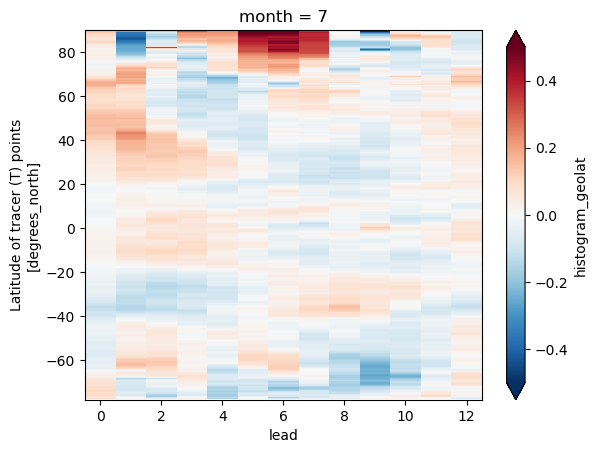

In [23]:
daanom_lonmean.sel(month=7,lead=slice(0,12)).transpose().plot(vmin=-0.5,vmax=0.5,cmap='RdBu_r')

## PPP difference between successive initializations for a given target month

In [24]:
static = esm4ppe.open_static('intpp','monthly')
ds = esm4ppe.open_verify('ocean','monthly','ppp',groupby='month')
masks = esm4ppe.get_masks('basin',static)

/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


In [25]:
da = ds[variable]
compareinits = ['AprJan','JulApr','OctJul']
forecastmonth = np.arange(1,36+1)
xh = da['xh']
yh = da['yh']
drho = xr.zeros_like(da.sel(month=4,lead=1).squeeze())
drho[:]=np.nan
drho = drho.expand_dims({'compareinits':compareinits,'forecastmonth':forecastmonth})
for f in drho['forecastmonth']:
    for i,m in enumerate(ds['month'][1:]):
        if (f-m)<0:
            continue
        c=compareinits[i]
        rho_upper = da.sel(month=m,lead=f-m+1)
        rho_lower = da.sel(month=m-3,lead=f-(m-3)+1)
        drho_values = rho_upper-rho_lower
        drho.loc[{'compareinits':c,'forecastmonth':f}]=drho_values

In [26]:
with ProgressBar():
    drho=drho.compute()

[########################################] | 100% Completed | 5.68 sms


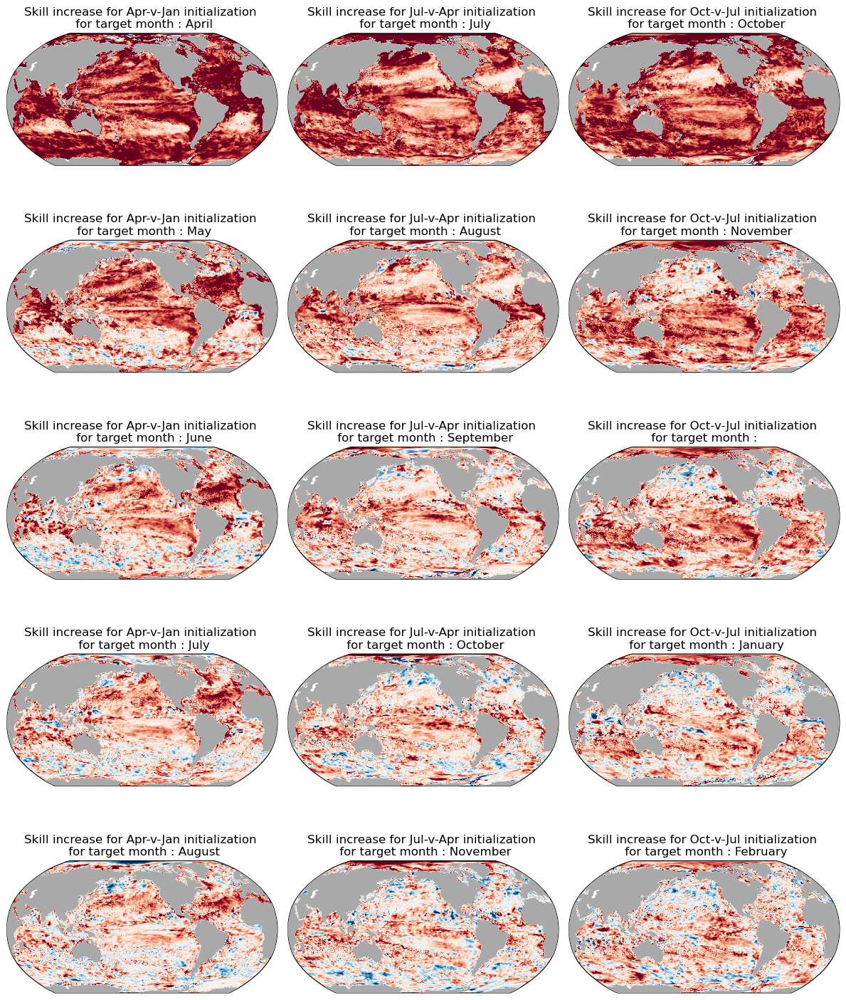

In [27]:
leads = [0,1,2,3,4]
latterinitmonth = [4,7,10]
kw_args = {'cmap':'RdBu_r','vmin':-0.5,'vmax':0.5, 'transform':ccrs.PlateCarree()}
nm = len(drho['compareinits'])
nl = len(leads)
fig,axarr = plt.subplots(figsize=(4*nm, 3*nl), ncols=nm, nrows=nl, subplot_kw={'projection':ccrs.Robinson(central_longitude=-150)})
X,Y = static['geolon'],static['geolat']
for i,lead in enumerate(leads):
    for j,c in enumerate(drho['compareinits']):
        forecastmonth = latterinitmonth[j]+lead
        axnow = axarr[i,j]
        Z = drho.sel(compareinits=c,forecastmonth=forecastmonth)
        im = axnow.pcolormesh(X,Y,Z,**kw_args)
        title="Skill increase for "+str(c.values)[:3]+"-v-"+str(c.values)[3:]+" initialization \n for target month : "+calendar.month_name[np.mod(forecastmonth,12)]
        axnow.set_title(title)
        axnow.add_feature(cartopy.feature.LAND,zorder=10,facecolor='darkgrey')
fig.tight_layout()

Positive values indicate that memory of the initialization date is retained. Looking down each column indicates how long that memory persists. Where positive values are retained in one column but not another indicates that there is a particular process occuring over that initialization gap that leads to a loss of memory, i.e. a predictability barrier. In a broad sense, it seems as though the deepening of the mixed layer is one such event, as evidenced by the unique strongly positive values in the subtropical and subpolar oceans for the initialization gaps corresponding to climatological deep MLDs (Apr-v-Jan and Oct-v-Jul). There are other interesting things happening in more specific regions, for example off the eastern African coast, in the northern Indian Ocean, and off the eastern Americas coast across the Jul-v-Apr gap.

## PPP anomaly at target month from different init months

### regional mean

In [28]:
ds = esm4ppe.open_verifyregionalmean('ocean','monthly','basin','ppp',groupby='month')

In [29]:
variable = 'intpp'
region = 'atlantic_NoSubP'

In [30]:
da = ds[variable].sel(region=region)
for month in da['month'].values:
    offset = month-1
    da.loc[{'month':month}] = da.sel(month=month).shift(lead=offset)
da = da.sel(lead=slice(1,36))

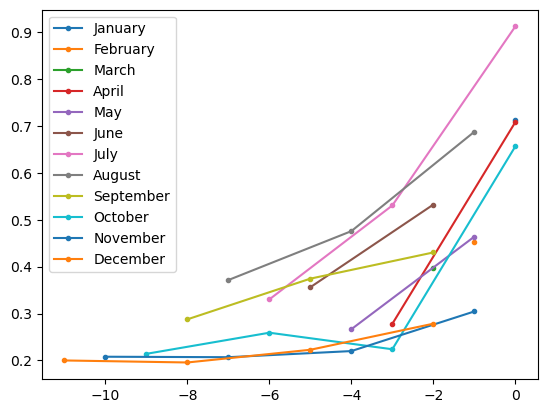

In [31]:
fig,ax = plt.subplots()
for forecastmonth in np.arange(1,13):
    ax.plot(-1*(forecastmonth-da.month),da.sel(lead=forecastmonth),marker='.',linestyle='-',label=calendar.month_name[forecastmonth])
ax.legend()
# da.sel(lead=forecastmonth).plot()

### global

In [32]:
static = esm4ppe.open_static('intpp','monthly')
ds = esm4ppe.open_verify('ocean','monthly','ppp',groupby='month')
masks = esm4ppe.get_masks('basin',static)

/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'thkcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(
/home/graemem/.conda/envs/climpred/lib/python3.11/site-packages/xarray/conventions.py:448: SerializationWarning: variable 'volcello' has multiple fill values {1e+20, 1e+20}, decoding all values to NaN.
  new_vars[k] = decode_cf_variable(


In [33]:
variable='intpp'
da = ds[variable]
for month in da['month'].values:
    offset = month-1
    da.loc[{'month':month}] = da.sel(month=month).shift(lead=offset)
da = da.sel(lead=slice(1,36))

In [34]:
daanom = da - da.sel(month=1).squeeze()
with ProgressBar():
    daanom = daanom.compute()

[########################################] | 100% Completed | 1.92 sms


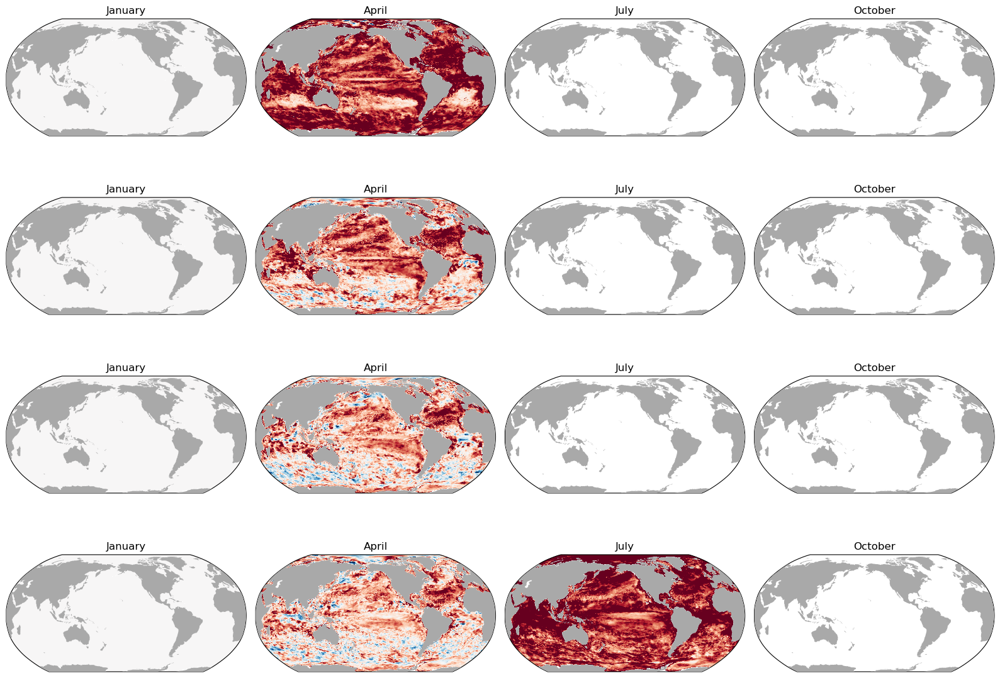

In [35]:
leads = [4,5,6,7]
kw_args = {'cmap':'RdBu_r','vmin':-0.5,'vmax':0.5, 'transform':ccrs.PlateCarree()}
nm = len(daanom['month'])
nl = len(leads)
fig,axarr = plt.subplots(figsize=(4*nm, 3*nl), ncols=nm, nrows=nl, subplot_kw={'projection':ccrs.Robinson(central_longitude=-150)})
X,Y = static['geolon'],static['geolat']
for i,lead in enumerate(leads):
    for j,month in enumerate(daanom['month']):
        axnow = axarr[i,j]
        Z = daanom.sel(month=month,lead=lead)
        im = axnow.pcolormesh(X,Y,Z,**kw_args)
        im.set_clim([-0.5,0.5])
        axnow.set_title(calendar.month_name[month.values])
        axnow.add_feature(cartopy.feature.LAND,zorder=10,facecolor='darkgrey')
fig.tight_layout()

In [36]:
# put all this into an array
import xarray as xr
n = 36
nfm = n
nl = n
tmp = np.empty(shape=(nfm,nl))
tmp[:]=np.nan
danow = xr.DataArray(tmp,
                     dims=['forecastmonth','lead'],
                     coords={'forecastmonth':np.arange(1,nfm+1),'lead':np.arange(0,nl)})
for forecastmonth in danow['forecastmonth']:
    leads = forecastmonth-da.month
    ppps = da.sel(lead=forecastmonth)
    # take finite ppp values
    leads = leads.where(np.isfinite(ppps.compute()),drop=True)
    ppps = ppps.where(np.isfinite(ppps.compute()),drop=True)
    # print(leads.values)
    danow.loc[{'lead':leads.values,'forecastmonth':forecastmonth}] = ppps.values
# danow = danow.assign_coords({'forecastmonth':list(calendar.month_name[1:])*3})

ValueError: Dimensions {'yh', 'xh'} do not exist. Expected one or more of FrozenMappingWarningOnValuesAccess({'month': 4})

In [ ]:
fig,ax = plt.subplots()
Z = (danow-danow.mean('forecastmonth')).transpose()
im = ax.pcolormesh(danow['forecastmonth'],
                   danow['lead']*-1,
                   Z,
                  cmap='RdBu_r')
im.set_clim([-0.2,0.2])
ax.set_xlabel('Forecast Month')
ax.tick_params(axis='x', labelrotation=90)
ax.set_ylabel('Lead time');
ax.grid()
plt.colorbar(im,ax=ax)

In [ ]:
danow.plot()

In [ ]:
fig,ax = plt.subplots()
ax.plot(-1*(da.lead-da.month),da

In [ ]:
da.lead.values

Produce for global data

In [ ]:
ds = esm4ppe.open_verify('ocean','monthly','ppp',groupby='month')
variable = 'intpp'
da = ds[variable]
for month in da['month'].values:
    offset = month-1
    da.loc[{'month':month}] = da.sel(month=month).shift(lead=offset)
da = da.sel(lead=slice(1,36))
distance = da.std(dim='month',skipna=True)

In [ ]:
distance.sel(lead=12).plot(robust=True)

In [ ]:
variable = 'intpp'
region = 'atlantic_NoSubT'
da = ds[variable].sel(region=region)
da.diff(dim='lead').plot(hue='month')

## Gradients in PPP (month when max occurs?)

In [8]:
static = esm4ppe.open_static('intpp','monthly')
ds = esm4ppe.open_verify('ocean','monthly','ppp',groupby='month')

In [9]:
variable='intpp'
da = ds[variable]
da

<xarray.DataArray 'intpp' (month: 4, lead: 120, yh: 576, xh: 720)>
dask.array<open_dataset-intpp, shape=(4, 120, 576, 720), dtype=float32, chunksize=(4, 120, 576, 720), chunktype=numpy.ndarray>
Coordinates:
  * lead     (lead) int64 1 2 3 4 5 6 7 8 9 ... 113 114 115 116 117 118 119 120
  * xh       (xh) float64 -299.8 -299.2 -298.8 -298.2 ... 58.75 59.25 59.75
  * yh       (yh) float64 -77.91 -77.72 -77.54 -77.36 ... 89.47 89.68 89.89
  * month    (month) int64 1 4 7 10

In [60]:
dad = da.diff('lead',label='lower')
dada = (dad - dad.mean('month'))
dada

<xarray.DataArray 'intpp' (month: 4, lead: 119, yh: 576, xh: 720)>
dask.array<sub, shape=(4, 119, 576, 720), dtype=float32, chunksize=(4, 119, 576, 720), chunktype=numpy.ndarray>
Coordinates:
  * lead     (lead) int64 1 2 3 4 5 6 7 8 9 ... 112 113 114 115 116 117 118 119
  * xh       (xh) float64 -299.8 -299.2 -298.8 -298.2 ... 58.75 59.25 59.75
  * yh       (yh) float64 -77.91 -77.72 -77.54 -77.36 ... 89.47 89.68 89.89
  * month    (month) int64 1 4 7 10

In [61]:
with ProgressBar():
    dada = dada.compute()

[########################################] | 100% Completed | 2.77 sms


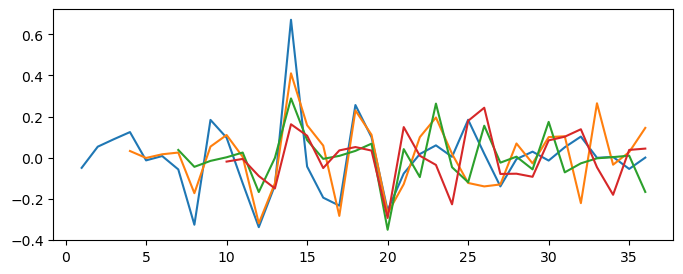

In [62]:
fig,ax = plt.subplots(figsize=(8,3))
for month in dada['month']:
    danow = dada.sel(month=month,xh=-150,yh=0,method='nearest').isel(lead=slice(0,36)).shift(lead=month.values-1)
    ax.plot(danow['lead'],danow)

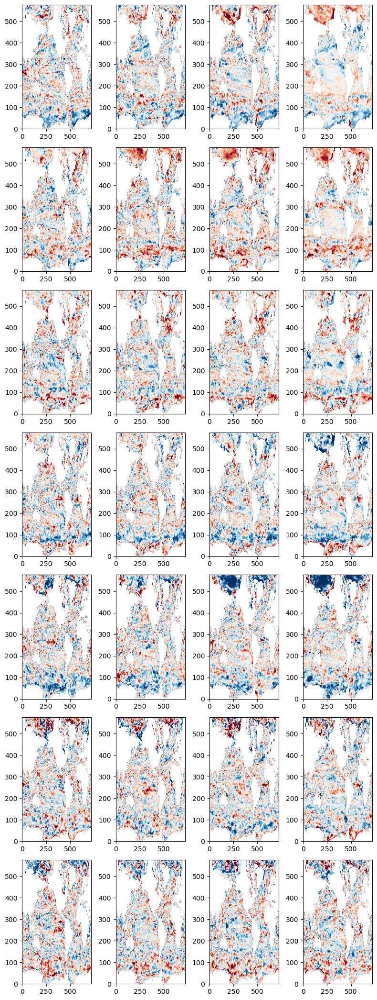

In [76]:
nlead = 7
fig,ax = plt.subplots(figsize=(8,3*nlead),nrows=nlead, ncols=4)
for i,month in enumerate(dada['month']):
    danow = dada.sel(month=month,method='nearest').isel(lead=slice(0,36)).shift(lead=month.values-1)
    for j in range(nlead):
        im = ax[j,i].pcolormesh(danow.sel(lead=10+j))
        im.set_clim([-0.5,0.5])
        im.set_cmap('RdBu_r')
        
fig.tight_layout()

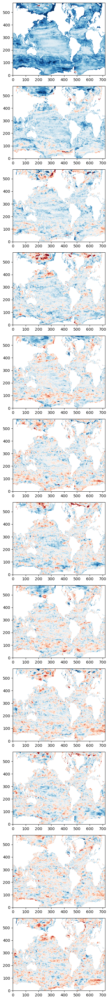

In [73]:
nlead = 12
fig,ax = plt.subplots(figsize=(4,3*nlead),nrows=nlead)
dadmean = dad.mean('month')
for j in range(nlead):
    im = ax[j].pcolormesh(dadmean.isel(lead=j))
    im.set_clim([-0.5,0.5])
    im.set_cmap('RdBu_r')
fig.tight_layout()